# Character-Level Language Models: Bigram vs. LSTM vs. Transformer

Name: Sijie Zhou

All three models are trained on the same dataset for the same task:
predict the next character from the previous context.

Dataset: *The Adventures of Sherlock Holmes* and *The Memoirs of Sherlock Holmes* by Arthur Conan Doyle (Project Gutenberg, public domain).

## 1. Setup

In [ ]:
import os
import re
import json
import math
import time
import urllib.request

import torch
import torch.nn as nn
import torch.nn.functional as F

# Shared settings for all three models
SEED = 42
BATCH_SIZE = 64
BLOCK_SIZE = 128
EVAL_ITERS = 200
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

torch.manual_seed(SEED)
print("Device:", DEVICE)
if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


## 2. Data

Download both books, remove the Gutenberg header and footer, and join them into one file.
If the download fails, get the "Plain Text UTF-8" files from
https://www.gutenberg.org/ebooks/1661 and https://www.gutenberg.org/ebooks/834
and put them in `data/raw/` as `adventures.txt` and `memoirs.txt`.

In [ ]:
DATA_PATH = "data/holmes.txt"
RAW_DIR = "data/raw"
BOOKS = {
    "adventures": "https://www.gutenberg.org/cache/epub/1661/pg1661.txt",
    "memoirs": "https://www.gutenberg.org/cache/epub/834/pg834.txt",
}

def strip_gutenberg(text):
    # Keep only the text between the START and END markers
    start = re.search(r"\*\*\* ?START OF.*?\*\*\*", text)
    end = re.search(r"\*\*\* ?END OF.*?\*\*\*", text)
    if start and end:
        text = text[start.end():end.start()]
    return text.strip()

if not os.path.exists(DATA_PATH):
    os.makedirs(RAW_DIR, exist_ok=True)
    parts = []
    for name, url in BOOKS.items():
        path = f"{RAW_DIR}/{name}.txt"
        if not os.path.exists(path):
            print(f"Downloading {name} ...")
            urllib.request.urlretrieve(url, path)
        with open(path, "r", encoding="utf-8-sig") as f:
            raw = f.read().replace("\r\n", "\n")
        parts.append(strip_gutenberg(raw))
    with open(DATA_PATH, "w", encoding="utf-8") as f:
        f.write("\n\n".join(parts))

with open(DATA_PATH, "r", encoding="utf-8") as f:
    text = f.read()

print(f"Total characters: {len(text):,}")
print(text[:500])

Total characters: 1,131,757
The Adventures of Sherlock Holmes

by Arthur Conan Doyle


Contents

   I.     A Scandal in Bohemia
   II.    The Red-Headed League
   III.   A Case of Identity
   IV.    The Boscombe Valley Mystery
   V.     The Five Orange Pips
   VI.    The Man with the Twisted Lip
   VII.   The Adventure of the Blue Carbuncle
   VIII.  The Adventure of the Speckled Band
   IX.    The Adventure of the Engineer’s Thumb
   X.     The Adventure of the Noble Bachelor
   XI.    The Adventure of the Beryl Coronet
 


### 2.1 Character encoding

In [ ]:
chars = sorted(set(text))
vocab_size = len(chars)
stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for i, ch in enumerate(chars)}

def encode(s):
    return [stoi[c] for c in s]

def decode(ids):
    return "".join(itos[i] for i in ids)

print("Vocab size:", vocab_size)
print("Characters:", repr("".join(chars)))
print("Curly quotes:", text.count("“"), text.count("”"))
print("Straight quotes:", text.count('"'))
print(decode(encode("Holmes")))

Vocab size: 91
Characters: '\n !&(),-.0123456789:;?ABCDEFGHIJKLMNOPQRSTUVWXYZ_abcdefghijklmnopqrstuvwxyz£º½àâæèéîôœ—‘’“”'
Curly quotes: 5126 4027
Straight quotes: 0
Holmes


### 2.2 Train/validation split

The split is sequential (first 90% train, last 10% validation), not shuffled.
A random split would let training and validation chunks overlap.

In [ ]:
data = torch.tensor(encode(text), dtype=torch.long)
n = int(0.9 * len(data))
train_data = data[:n]
val_data = data[n:]
print(f"Train: {len(train_data):,} | Val: {len(val_data):,}")

Train: 1,018,581 | Val: 113,176


## 3. Shared training tools

In [ ]:
def get_batch(split):
    source = train_data if split == "train" else val_data
    ix = torch.randint(len(source) - BLOCK_SIZE, (BATCH_SIZE,))
    x = torch.stack([source[i:i + BLOCK_SIZE] for i in ix])
    y = torch.stack([source[i + 1:i + BLOCK_SIZE + 1] for i in ix])
    return x.to(DEVICE), y.to(DEVICE)

xb, yb = get_batch("train")
print(xb.shape, yb.shape)
print(repr(decode(xb[0][:40].tolist())))
print(repr(decode(yb[0][:40].tolist())))  # shifted by one character

torch.Size([64, 128]) torch.Size([64, 128])
'sing-room. Petrified with astonishment, '
'ing-room. Petrified with astonishment, t'


In [ ]:
@torch.no_grad()
def estimate_loss(model):
    # Average loss over EVAL_ITERS random batches
    model.eval()
    out = {}
    for split in ("train", "val"):
        losses = torch.zeros(EVAL_ITERS)
        for k in range(EVAL_ITERS):
            x, y = get_batch(split)
            _, loss = model(x, y)
            losses[k] = loss.item()
        out[split] = losses.mean().item()
    model.train()
    return out


def _sync():
    if DEVICE == "cuda":
        torch.cuda.synchronize()


def train(model, max_iters=5000, eval_interval=500, lr=1e-3):
    # train_time counts training steps only, not evaluation
    torch.manual_seed(SEED)
    model.to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr)
    history = {"step": [], "train_loss": [], "val_loss": []}
    train_time = 0.0

    def log(step):
        losses = estimate_loss(model)
        history["step"].append(step)
        history["train_loss"].append(losses["train"])
        history["val_loss"].append(losses["val"])
        print(f"step {step:5d} | train {losses['train']:.4f} | "
              f"val {losses['val']:.4f} | train time {train_time:.1f}s")

    t0 = None
    for step in range(max_iters):
        if step % eval_interval == 0:
            if t0 is not None:
                _sync()
                train_time += time.perf_counter() - t0
            log(step)
            _sync()
            t0 = time.perf_counter()

        x, y = get_batch("train")
        _, loss = model(x, y)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()

    _sync()
    train_time += time.perf_counter() - t0
    log(max_iters)
    return history, train_time

In [ ]:
@torch.no_grad()
def generate(model, max_new_tokens=500, start="\n", temperature=1.0):
    # Sample one character at a time; the model sees at most BLOCK_SIZE characters
    model.eval()
    torch.manual_seed(SEED)
    idx = torch.tensor([encode(start)], dtype=torch.long, device=DEVICE)
    for _ in range(max_new_tokens):
        idx_cond = idx[:, -BLOCK_SIZE:]
        logits, _ = model(idx_cond)
        logits = logits[:, -1, :] / temperature
        probs = F.softmax(logits, dim=-1)
        next_id = torch.multinomial(probs, num_samples=1)
        idx = torch.cat([idx, next_id], dim=1)
    model.train()
    return decode(idx[0].tolist())


def save_results(name, model, history, train_time, sample, lr):
    os.makedirs("results", exist_ok=True)
    os.makedirs("samples", exist_ok=True)
    n_params = sum(p.numel() for p in model.parameters())
    result = {
        "model": name,
        "params": n_params,
        "final_train_loss": round(history["train_loss"][-1], 4),
        "final_val_loss": round(history["val_loss"][-1], 4),
        "train_time_sec": round(train_time, 1),
        "device": torch.cuda.get_device_name(0) if DEVICE == "cuda" else "cpu",
        "max_iters": history["step"][-1],
        "batch_size": BATCH_SIZE,
        "block_size": BLOCK_SIZE,
        "lr": lr,
        "history": history,
    }
    with open(f"results/{name}.json", "w", encoding="utf-8") as f:
        json.dump(result, f, indent=2)
    with open(f"samples/{name}.txt", "w", encoding="utf-8") as f:
        f.write(sample)
    print(f"Saved results/{name}.json and samples/{name}.txt")
    print(f"params={n_params:,} | val loss={result['final_val_loss']} | "
          f"time={result['train_time_sec']}s")
    return result

## 4. Model 1: Bigram

The model is a `vocab_size × vocab_size` lookup table.
Row *i* holds the scores for the next character when the current character is *i*.

In [ ]:
class BigramLM(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()
        self.table = nn.Embedding(vocab_size, vocab_size)
        nn.init.normal_(self.table.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        logits = self.table(idx)  # (B, T, vocab_size); each position sees only itself
        loss = None
        if targets is not None:
            B, T, C = logits.shape
            loss = F.cross_entropy(logits.view(B * T, C), targets.view(B * T))
        return logits, loss


torch.manual_seed(SEED)
bigram = BigramLM(vocab_size).to(DEVICE)

# Sanity check: an untrained model guesses uniformly, so loss ≈ ln(vocab_size)
print(f"Expected initial loss ≈ ln({vocab_size}) = {math.log(vocab_size):.4f}")
print(f"Actual initial loss:   {estimate_loss(bigram)['val']:.4f}")

Expected initial loss ≈ ln(91) = 4.5109
Actual initial loss:   4.5144


In [ ]:
BIGRAM_LR = 1e-2
bigram_history, bigram_time = train(bigram, max_iters=5000, eval_interval=500, lr=BIGRAM_LR)

step     0 | train 4.5128 | val 4.5144 | train time 0.0s
step   500 | train 2.4860 | val 2.4373 | train time 1.7s
step  1000 | train 2.4430 | val 2.3939 | train time 3.7s
step  1500 | train 2.4332 | val 2.3821 | train time 5.3s
step  2000 | train 2.4278 | val 2.3819 | train time 6.9s
step  2500 | train 2.4274 | val 2.3790 | train time 8.4s
step  3000 | train 2.4254 | val 2.3754 | train time 10.0s
step  3500 | train 2.4240 | val 2.3776 | train time 11.9s
step  4000 | train 2.4231 | val 2.3741 | train time 13.6s
step  4500 | train 2.4242 | val 2.3783 | train time 15.2s
step  5000 | train 2.4229 | val 2.3783 | train time 16.7s


In [ ]:
bigram_sample = generate(bigram, max_new_tokens=500)
print(bigram_sample)






 ane d s tof
d cre sse cr amyougeta sustond,
quthescave-nty nthefrmaingrer?”

aghilef
was bvas I   or, Ba alon  I fascat urete ofise by.

cind  hik,  s rtyowede col, d abr. wid t ust me whe
shela ing my  h ha thegid t walinch, tenistaby anochas ss whowre5  by.’
t and   shen igosas; thed ayexthisunde   g s.”
  hougre fo-ndf tske btou yobed hatheapth ctn  d o resthe wngrver s
 ivele setes m
 I nmin scere ttiler Pr, o ithicangen Ma hifons ngeroshenisaian, toly, cthif
ad aindrid itin  ker d  the


In [ ]:
bigram_result = save_results("bigram", bigram, bigram_history, bigram_time,
                             bigram_sample, lr=BIGRAM_LR)

Saved results/bigram.json and samples/bigram.txt
params=8,281 | val loss=2.3783 | time=16.7s


### Bigram: discussion

- **What information it uses:** It uses only the current character.
- **What information it ignores:** Most of the “words” don’t exist—for example, amyougeta, quthescave, and ngeroshenisaian. Since the model only looks at the previous letter at each step, it doesn’t know which word it’s spelling or how many letters of that word have already been spelled, so it eventually goes off track. The sentences make no sense and lack grammar. There’s no connection between words because the model can’t see the previous word at all.
- **Why its language understanding is limited:** You can only learn partial combinations of letters; you can’t learn words, grammar, or long-range structures. When the model generates “, it doesn’t know whether a conversation has already begun; it only knows that a period or question mark is often followed by ”

## 5. Model 2: LSTM

Embedding → 2-layer LSTM → linear output layer.
The LSTM reads the context from left to right.
Its hidden state carries information from earlier characters (up to `BLOCK_SIZE` = 128) to later positions.

In [ ]:
class LSTMLM(nn.Module):
    def __init__(self, vocab_size, n_embd=128, hidden_size=256, num_layers=2, dropout=0.2):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, n_embd)
        self.lstm = nn.LSTM(
            input_size=n_embd,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout,
        )
        self.head = nn.Linear(hidden_size, vocab_size)

    def forward(self, idx, targets=None):
        x = self.embedding(idx)   # (B, T, n_embd)
        out, _ = self.lstm(x)     # (B, T, hidden_size); position t has seen characters 0..t
        logits = self.head(out)   # (B, T, vocab_size)
        loss = None
        if targets is not None:
            B, T, C = logits.shape
            loss = F.cross_entropy(logits.view(B * T, C), targets.view(B * T))
        return logits, loss


torch.manual_seed(SEED)
lstm = LSTMLM(vocab_size).to(DEVICE)

print(f"Parameters: {sum(p.numel() for p in lstm.parameters()):,}")
print(f"Expected initial loss ≈ ln({vocab_size}) = {math.log(vocab_size):.4f}")
print(f"Actual initial loss:   {estimate_loss(lstm)['val']:.4f}")

Parameters: 956,635
Expected initial loss ≈ ln(91) = 4.5109
Actual initial loss:   4.5047


In [ ]:
LSTM_LR = 2e-3
lstm_history, lstm_time = train(lstm, max_iters=5000, eval_interval=500, lr=LSTM_LR)

step     0 | train 4.5058 | val 4.5048 | train time 0.0s
step   500 | train 1.5345 | val 1.4623 | train time 11.2s
step  1000 | train 1.3557 | val 1.3186 | train time 22.6s
step  1500 | train 1.2712 | val 1.2515 | train time 34.5s
step  2000 | train 1.2171 | val 1.2171 | train time 46.7s
step  2500 | train 1.1818 | val 1.1954 | train time 58.7s
step  3000 | train 1.1478 | val 1.1755 | train time 70.5s
step  3500 | train 1.1210 | val 1.1695 | train time 82.3s
step  4000 | train 1.1057 | val 1.1627 | train time 94.2s
step  4500 | train 1.0885 | val 1.1627 | train time 106.2s
step  5000 | train 1.0715 | val 1.1542 | train time 118.1s


In [ ]:
lstm_sample = generate(lstm, max_new_tokens=500)
print(lstm_sample)



“They were that, horrorse crops I get away to the other.”

“Prentry, married Streathred,” said I, ‘yes, as it look upon the uppose,
is introduced in the straggled towards the crime, and my wife has been my sherry
      to me not, then the cap that some observer, and an the old is
sas which I extend of our silence, with a stock should be in the ratker. It
      restem to your small, has telled. In in the matter.”

      They were to his wife I had neiding to be one week. I had done a profeder
  


In [ ]:
lstm_result = save_results("lstm", lstm, lstm_history, lstm_time,
                           lstm_sample, lr=LSTM_LR)

Saved results/lstm.json and samples/lstm.txt
params=956,635 | val loss=1.1542 | time=118.1s


In [ ]:
# Quote check: are opening and closing quotes balanced?
for name, sample in [("bigram", bigram_sample), ("lstm", lstm_sample)]:
    print(f"{name:7s} “ {sample.count('“'):3d} | ” {sample.count('”'):3d}")

bigram  “   0 | ”   2
lstm    “   2 | ”   3


### LSTM: discussion

- **How it uses more context than the bigram model:** Bigram can barely spell words longer than three letters, while LSTM is already able to consistently spell out entire long words, indicating that it remembers “how far along it is in spelling the current word.”
- **What improvement it provides:** It has learned the writing style of the original text. Since the Sherlock Holmes stories are narrated by Watson in the first person, the model has picked up the frequent use of phrases like “said I” and “my wife” found in the original. The local syntax is generally coherent. Phrases like “I get away to the other,” “which I extend of our silence,” and “I had done a”—when looked at word by word—appear to be English.
- **Why it may still struggle with longer dependencies:** LSTM can handle the relationships between individual words, but it cannot handle entire sentences or paragraphs. There are also some non-existent words, such as “horrorse,” “uppose,” “ratker,” “restem,” “neiding,” and “profeder.” Most of them “resemble” real words—for example, “telled” is the past tense of “tell” formed according to the rules, and “profeder” resembles “professor” or “proffered.” This indicates that the model has learned the patterns of English word formation but has not accurately memorized every single word.

## 6. Model 3: Small Transformer

A small decoder-only (GPT-style) transformer with the five required parts:

1. **Token embeddings** — each character becomes a learned vector.
2. **Positional information** — a learned vector for each position (0 to 127), added to the token vector.
3. **Self-attention** — causal multi-head attention. Each position can look at every earlier position directly.
4. **Feedforward layer** — a two-layer MLP applied to each position.
5. **Output layer** — final LayerNorm and a linear layer that gives a score for each character.

Each block uses pre-LayerNorm and residual connections.
Size: 4 layers, 4 heads, 128-dim embeddings.

In [ ]:
N_EMBD = 128
N_HEAD = 4
N_LAYER = 4
TF_DROPOUT = 0.2


class CausalSelfAttention(nn.Module):
    def __init__(self, n_embd, n_head, dropout):
        super().__init__()
        assert n_embd % n_head == 0
        self.n_head = n_head
        self.head_size = n_embd // n_head
        self.qkv = nn.Linear(n_embd, 3 * n_embd, bias=False)  # query, key, value for all heads
        self.proj = nn.Linear(n_embd, n_embd)
        self.attn_drop = nn.Dropout(dropout)
        self.resid_drop = nn.Dropout(dropout)
        # Lower-triangular mask: position t may only attend to positions 0..t
        mask = torch.tril(torch.ones(BLOCK_SIZE, BLOCK_SIZE))
        self.register_buffer("mask", mask.view(1, 1, BLOCK_SIZE, BLOCK_SIZE))

    def forward(self, x):
        B, T, C = x.shape
        q, k, v = self.qkv(x).split(C, dim=2)
        # (B, T, C) -> (B, n_head, T, head_size)
        q = q.view(B, T, self.n_head, self.head_size).transpose(1, 2)
        k = k.view(B, T, self.n_head, self.head_size).transpose(1, 2)
        v = v.view(B, T, self.n_head, self.head_size).transpose(1, 2)

        # Attention scores: how much each position should look at each earlier position
        att = (q @ k.transpose(-2, -1)) / math.sqrt(self.head_size)   # (B, n_head, T, T)
        att = att.masked_fill(self.mask[:, :, :T, :T] == 0, float("-inf"))
        att = F.softmax(att, dim=-1)
        att = self.attn_drop(att)

        out = att @ v                                            # (B, n_head, T, head_size)
        out = out.transpose(1, 2).contiguous().view(B, T, C)     # join the heads
        return self.resid_drop(self.proj(out))


class FeedForward(nn.Module):
    def __init__(self, n_embd, dropout):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.GELU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)


class Block(nn.Module):
    def __init__(self, n_embd, n_head, dropout):
        super().__init__()
        self.ln1 = nn.LayerNorm(n_embd)
        self.attn = CausalSelfAttention(n_embd, n_head, dropout)
        self.ln2 = nn.LayerNorm(n_embd)
        self.ffwd = FeedForward(n_embd, dropout)

    def forward(self, x):
        x = x + self.attn(self.ln1(x))   # positions share information
        x = x + self.ffwd(self.ln2(x))   # each position processes what it gathered
        return x


class TransformerLM(nn.Module):
    def __init__(self, vocab_size, n_embd=N_EMBD, n_head=N_HEAD,
                 n_layer=N_LAYER, dropout=TF_DROPOUT):
        super().__init__()
        self.tok_emb = nn.Embedding(vocab_size, n_embd)    # 1. token embeddings
        self.pos_emb = nn.Embedding(BLOCK_SIZE, n_embd)    # 2. positional information
        self.drop = nn.Dropout(dropout)
        self.blocks = nn.Sequential(                       # 3 + 4. attention and feedforward
            *[Block(n_embd, n_head, dropout) for _ in range(n_layer)]
        )
        self.ln_f = nn.LayerNorm(n_embd)                   # 5. output layer
        self.head = nn.Linear(n_embd, vocab_size)
        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, (nn.Linear, nn.Embedding)):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
        if isinstance(module, nn.Linear) and module.bias is not None:
            nn.init.zeros_(module.bias)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        pos = torch.arange(T, device=idx.device)
        x = self.tok_emb(idx) + self.pos_emb(pos)   # (B, T, n_embd)
        x = self.drop(x)
        x = self.blocks(x)
        x = self.ln_f(x)
        logits = self.head(x)                       # (B, T, vocab_size)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(B * T, -1), targets.view(B * T))
        return logits, loss


torch.manual_seed(SEED)
transformer = TransformerLM(vocab_size).to(DEVICE)

print(f"Parameters: {sum(p.numel() for p in transformer.parameters()):,}")
print(f"Expected initial loss ≈ ln({vocab_size}) = {math.log(vocab_size):.4f}")
print(f"Actual initial loss:   {estimate_loss(transformer)['val']:.4f}")

Parameters: 831,579
Expected initial loss ≈ ln(91) = 4.5109
Actual initial loss:   4.6014


In [ ]:
TF_LR = 1e-3
tf_history, tf_time = train(transformer, max_iters=5000, eval_interval=500, lr=TF_LR)

step     0 | train 4.5907 | val 4.6013 | train time 0.0s
step   500 | train 1.9410 | val 1.8375 | train time 15.2s
step  1000 | train 1.5994 | val 1.5177 | train time 30.0s
step  1500 | train 1.4527 | val 1.3923 | train time 45.0s
step  2000 | train 1.3619 | val 1.3177 | train time 60.3s
step  2500 | train 1.3122 | val 1.2765 | train time 75.7s
step  3000 | train 1.2733 | val 1.2462 | train time 91.1s
step  3500 | train 1.2470 | val 1.2296 | train time 106.4s
step  4000 | train 1.2271 | val 1.2113 | train time 121.8s
step  4500 | train 1.2112 | val 1.2020 | train time 137.4s
step  5000 | train 1.1978 | val 1.1935 | train time 152.9s


In [ ]:
tf_sample = generate(transformer, max_new_tokens=500)
print(tf_sample)


what seemed to for me.”

“I’re I have a sure adverything very remarkable thing?”

“Ah, I am staken to to adverty I have seen upon my own brands. The
would not find that, I am a question told my sheer in young marriage, at
the grey that this man, I was quite impressence that he will, such the
wedding of our silence, but if I had seen to us either. Had been hundred stretch
my tremains had to happy thin to me. Silence too remark me with no
describest?”

“Why, told you well be serious,” said Holmes.


In [ ]:
tf_result = save_results("transformer", transformer, tf_history, tf_time,
                         tf_sample, lr=TF_LR)

Saved results/transformer.json and samples/transformer.txt
params=831,579 | val loss=1.1935 | time=152.9s


In [ ]:
# Quote check for all three models
for name, sample in [("bigram", bigram_sample), ("lstm", lstm_sample), ("transformer", tf_sample)]:
    print(f"{name:12s} “ {sample.count('“'):3d} | ” {sample.count('”'):3d} | "
          f"‘ {sample.count('‘'):3d} | ’ {sample.count('’'):3d}")

bigram       “   0 | ”   2 | ‘   0 | ’   1
lstm         “   2 | ”   3 | ‘   1 | ’   0
transformer  “   3 | ”   4 | ‘   0 | ’   1


### Transformer: discussion

- **What the transformer improved compared to the other models:** The dialogue structure is more complete. This passage consists almost entirely of dialogue; each paragraph begins with “ and ends with ,” with a blank line between paragraphs, and concludes with “Why, I told you we’d be serious,” said Holmes. The format—“quotation marks + comma + said + name”—is entirely correct, and the speaker is Holmes, whose name is spelled out in full.
- **What I learned about attention:** Attention allows the model, when predicting each character, to decide on its own which previous positions to look at based on the content, and to directly access any position within the window.

## 7. Comparison


### 7.1 Results table

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

MODELS = ["bigram", "lstm", "transformer"]
all_results = {}
for name in MODELS:
    with open(f"results/{name}.json", encoding="utf-8") as f:
        all_results[name] = json.load(f)

rows = []
for name, r in all_results.items():
    rows.append({
        "Model": name,
        "Params": r["params"],
        "Train loss": r["final_train_loss"],
        "Val loss": r["final_val_loss"],
        "Val perplexity": round(math.exp(r["final_val_loss"]), 2),
        "Gap (val - train)": round(r["final_val_loss"] - r["final_train_loss"], 4),
        "Train time (s)": r["train_time_sec"],
        "Device": r["device"],
    })
df = pd.DataFrame(rows)
display(df)

# Save as a Markdown table for the README
cols = list(df.columns)
lines = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
for _, row in df.iterrows():
    cells = [f"{int(row[c]):,}" if c == "Params" else str(row[c]) for c in cols]
    lines.append("| " + " | ".join(cells) + " |")
with open("results/results_table.md", "w", encoding="utf-8") as f:
    f.write("\n".join(lines) + "\n")
print("\n".join(lines))

,Model,Params,Train loss,Val loss,Val perplexity,Gap (val - train),Train time (s),Device
0,bigram,8281,2.4229,2.3783,10.79,-0.0446,16.7,Tesla T4
1,lstm,956635,1.0715,1.1542,3.17,0.0827,118.1,Tesla T4
2,transformer,831579,1.1978,1.1935,3.30,-0.0043,152.9,Tesla T4


| Model | Params | Train loss | Val loss | Val perplexity | Gap (val - train) | Train time (s) | Device |
|---|---|---|---|---|---|---|---|
| bigram | 8,281 | 2.4229 | 2.3783 | 10.79 | -0.0446 | 16.7 | Tesla T4 |
| lstm | 956,635 | 1.0715 | 1.1542 | 3.17 | 0.0827 | 118.1 | Tesla T4 |
| transformer | 831,579 | 1.1978 | 1.1935 | 3.3 | -0.0043 | 152.9 | Tesla T4 |


### 7.2 Loss curves

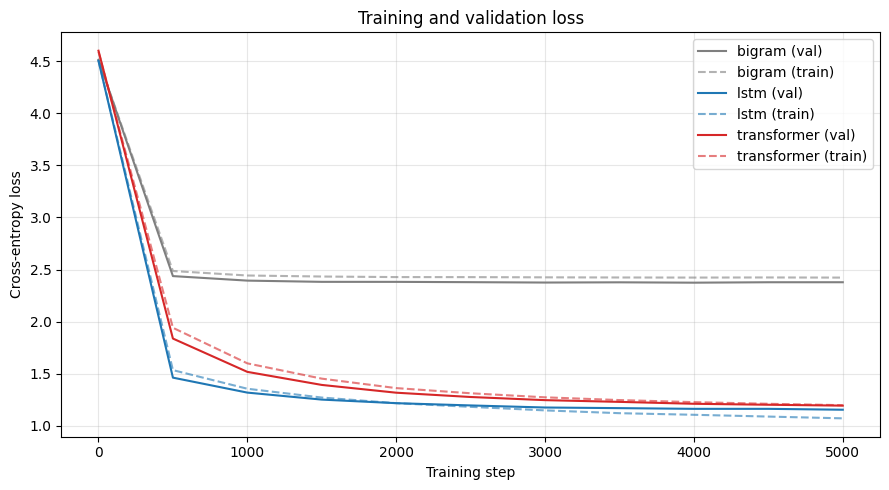

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))
colors = {"bigram": "tab:gray", "lstm": "tab:blue", "transformer": "tab:red"}
for name, r in all_results.items():
    h = r["history"]
    ax.plot(h["step"], h["val_loss"], color=colors[name], label=f"{name} (val)")
    ax.plot(h["step"], h["train_loss"], color=colors[name], linestyle="--",
            alpha=0.6, label=f"{name} (train)")
ax.set_xlabel("Training step")
ax.set_ylabel("Cross-entropy loss")
ax.set_title("Training and validation loss")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig("results/loss_curves.png", dpi=150)
plt.show()

### 7.3 Generated text

Each model generates 3,000 characters from the same seed.
Two simple measures of quality:

- **Real-word rate:** share of generated words that also appear in the training text.
- **Quote balance:** number of opening “ and closing ” quotes. A large gap means the model loses track of dialogue.

In [ ]:
import re

real_words = set(re.findall(r"[a-z]+", text.lower()))

def word_validity(sample):
    words = re.findall(r"[a-z]+", sample.lower())
    return sum(w in real_words for w in words) / max(len(words), 1)

trained = {"bigram": bigram, "lstm": lstm, "transformer": transformer}
quality_rows = []
long_samples = {}
for name, model in trained.items():
    s = generate(model, max_new_tokens=3000)
    long_samples[name] = s
    with open(f"samples/{name}_long.txt", "w", encoding="utf-8") as f:
        f.write(s)
    quality_rows.append({
        "Model": name,
        "Real-word rate": f"{word_validity(s):.1%}",
        "“ count": s.count("“"),
        "” count": s.count("”"),
        "Quote gap": abs(s.count("“") - s.count("”")),
    })
display(pd.DataFrame(quality_rows))

,Model,Real-word rate,“ count,” count,Quote gap
0,bigram,37.5%,8,12,4
1,lstm,91.7%,2,3,1
2,transformer,89.4%,11,10,1


In [ ]:
# Short samples side by side (first 400 characters of each long sample)
for name, s in long_samples.items():
    print(f"========== {name} ==========")
    print(s[:400])
    print()

========== bigram ==========





 ane d s tof
d cre sse cr amyougeta sustond,
quthescave-nty nthefrmaingrer?”

aghilef
was bvas I   or, Ba alon  I fascat urete ofise by.

cind  hik,  s rtyowede col, d abr. wid t ust me whe
shela ing my  h ha thegid t walinch, tenistaby anochas ss whowre5  by.’
t and   shen igosas; thed ayexthisunde   g s.”
  hougre fo-ndf tske btou yobed hatheapth ctn  d o resthe wngrver s
 ivele setes m
 I 

========== lstm ==========


“They were that, horrorse crops I get away to the other.”

“Prentry, married Streathred,” said I, ‘yes, as it look upon the uppose,
is introduced in the straggled towards the crime, and my wife has been my sherry
      to me not, then the cap that some observer, and an the old is
sas which I extend of our silence, with a stock should be in the ratker. It
      restem to your small, has telled. I

========== transformer ==========

what seemed to for me.”

“I’re I have a sure adverything very remarkable thing?”

“Ah, I am staken to to 

### 7.4 Looking inside attention

Attention weights are computed from the trained transformer, without retraining.
Each row of a heatmap is a position (query); each column shows how much that position attends to an earlier position (key).
Spaces are shown as `_`.

In [ ]:
@torch.no_grad()
def get_attention(model, s, layer):
    # Returns attention weights of one layer: (n_head, T, T)
    model.eval()
    idx = torch.tensor([encode(s)], dtype=torch.long, device=DEVICE)
    T = idx.shape[1]
    x = model.tok_emb(idx) + model.pos_emb(torch.arange(T, device=DEVICE))
    for i, block in enumerate(model.blocks):
        if i == layer:
            attn = block.attn
            h = block.ln1(x)
            q, k, _ = attn.qkv(h).split(h.shape[-1], dim=2)
            q = q.view(1, T, attn.n_head, attn.head_size).transpose(1, 2)
            k = k.view(1, T, attn.n_head, attn.head_size).transpose(1, 2)
            att = (q @ k.transpose(-2, -1)) / math.sqrt(attn.head_size)
            att = att.masked_fill(attn.mask[:, :, :T, :T] == 0, float("-inf"))
            return F.softmax(att, dim=-1)[0].cpu()
        x = block(x)


def plot_attention(model, s, layer):
    att = get_attention(model, s, layer)
    labels = ["_" if c == " " else c for c in s]
    n_head = att.shape[0]
    fig, axes = plt.subplots(1, n_head, figsize=(4.5 * n_head, 4.5))
    for h, ax in enumerate(axes):
        ax.imshow(att[h], cmap="viridis")
        ax.set_title(f"Layer {layer}, head {h}")
        ax.set_xticks(range(len(s)))
        ax.set_xticklabels(labels, fontsize=6)
        ax.set_yticks(range(len(s)))
        ax.set_yticklabels(labels, fontsize=6)
    axes[0].set_ylabel("current position (query)")
    fig.supxlabel("earlier position it attends to (key)")
    plt.tight_layout()
    plt.savefig(f"results/attention_layer{layer}.png", dpi=150)
    plt.show()


def top_attention(model, s, k=5):
    # For the LAST character of s, show the k positions each head attends to most
    pos = len(s) - 1
    print(f"Text: {s!r}")
    print(f"Query: last character {s[pos]!r} (the model is predicting what comes next)\n")
    for layer in range(len(model.blocks)):
        att = get_attention(model, s, layer)
        for h in range(att.shape[0]):
            vals, ids = torch.topk(att[h, pos], min(k, pos + 1))
            items = ", ".join(f"{s[i]!r}@{int(i)} ({v:.2f})" for v, i in zip(vals, ids))
            print(f"layer {layer} head {h}: {items}")
    print()

Text: '“I have seen it before,” said Holmes. “It is quite clear.'
Query: last character '.' (the model is predicting what comes next)

layer 0 head 0: ' '@7 (0.41), ' '@15 (0.38), 'r'@55 (0.08), 'a'@4 (0.07), 's'@8 (0.02)
layer 0 head 1: 'a'@54 (1.00), 'r'@55 (0.00), 'c'@51 (0.00), ' '@37 (0.00), '.'@36 (0.00)
layer 0 head 2: 'r'@55 (1.00), '.'@56 (0.00), 'l'@52 (0.00), '“'@38 (0.00), 'a'@54 (0.00)
layer 0 head 3: '.'@56 (0.55), 'r'@55 (0.21), 'a'@54 (0.12), '“'@38 (0.03), 'e'@53 (0.02)
layer 1 head 0: 'q'@45 (0.12), 'l'@52 (0.11), 'c'@51 (0.09), '.'@56 (0.07), ' '@50 (0.05)
layer 1 head 1: 'a'@54 (0.53), 'I'@1 (0.07), 'c'@51 (0.07), 'q'@45 (0.06), 'r'@55 (0.06)
layer 1 head 2: ' '@2 (0.36), ' '@7 (0.23), '“'@0 (0.18), ' '@50 (0.10), '.'@56 (0.06)
layer 1 head 3: 'a'@54 (0.05), ' '@50 (0.04), 'q'@45 (0.04), ' '@7 (0.03), 'e'@53 (0.03)
layer 2 head 0: 'a'@54 (0.39), ' '@50 (0.15), 'l'@52 (0.11), '.'@56 (0.08), 'q'@45 (0.08)
layer 2 head 1: '“'@38 (0.99), '“'@0 (0.00), ' '@37 (0.00), 'I'

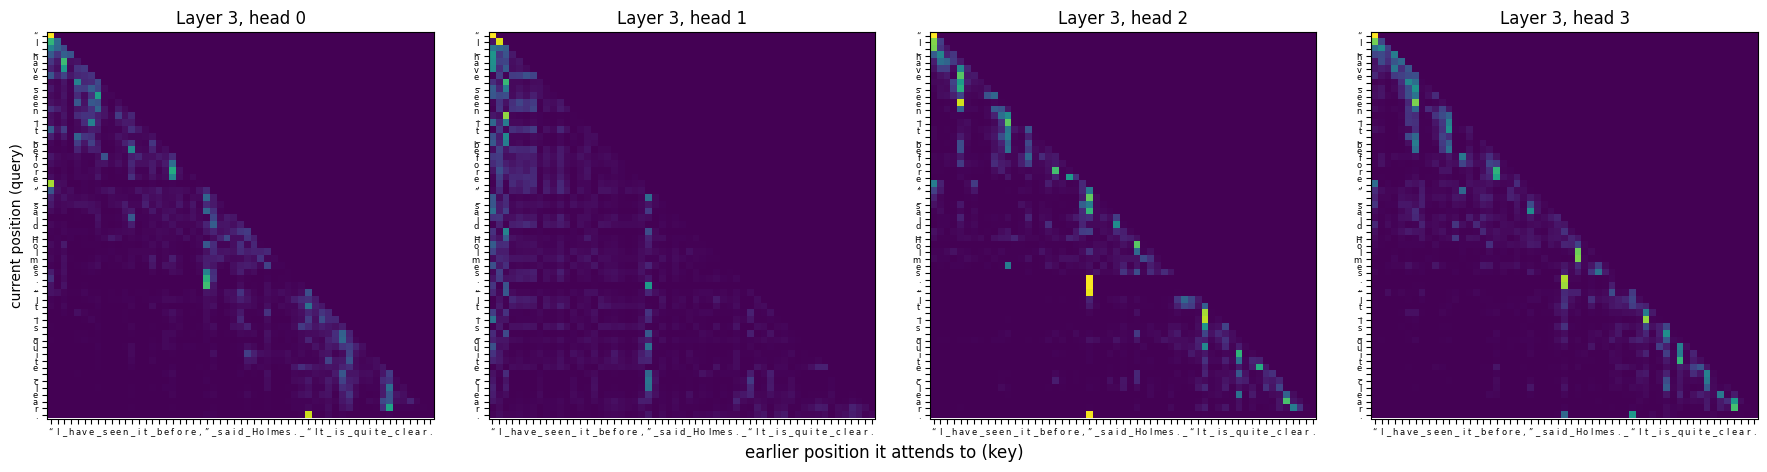

In [ ]:
# Example 1: inside a dialogue. Does any head look back at the opening quote?
example_quote = "“I have seen it before,” said Holmes. “It is quite clear."
top_attention(transformer, example_quote)
plot_attention(transformer, example_quote, layer=N_LAYER - 1)

Text: 'Holmes looked at me. I said nothing, and Hol'
Query: last character 'l' (the model is predicting what comes next)

layer 0 head 0: 'o'@42 (1.00), ' '@27 (0.00), 'n'@38 (0.00), 'l'@43 (0.00), 's'@23 (0.00)
layer 0 head 1: 'H'@41 (1.00), 'd'@26 (0.00), 'a'@37 (0.00), ' '@22 (0.00), 't'@15 (0.00)
layer 0 head 2: 'o'@42 (1.00), 'l'@43 (0.00), 'n'@38 (0.00), ' '@27 (0.00), 's'@23 (0.00)
layer 0 head 3: 'H'@41 (0.54), 'o'@42 (0.33), 'l'@43 (0.05), ' '@40 (0.01), 'd'@39 (0.01)
layer 1 head 0: 'H'@41 (0.18), 'd'@39 (0.10), ' '@40 (0.08), 'o'@42 (0.06), ','@35 (0.06)
layer 1 head 1: 'o'@42 (1.00), 'o'@1 (0.00), 'o'@29 (0.00), 'l'@43 (0.00), 'o'@8 (0.00)
layer 1 head 2: 'o'@42 (0.90), 'H'@41 (0.10), 'l'@43 (0.00), 'o'@1 (0.00), 'o'@8 (0.00)
layer 1 head 3: 'H'@0 (0.08), 'H'@41 (0.05), 'o'@1 (0.04), ','@35 (0.04), 's'@5 (0.04)
layer 2 head 0: 'o'@42 (0.58), 'H'@41 (0.23), 'l'@43 (0.11), ','@35 (0.02), 'a'@37 (0.02)
layer 2 head 1: 'n'@38 (0.32), 'o'@42 (0.17), 'H'@41 (0.13), 'i'@25 (0.10),

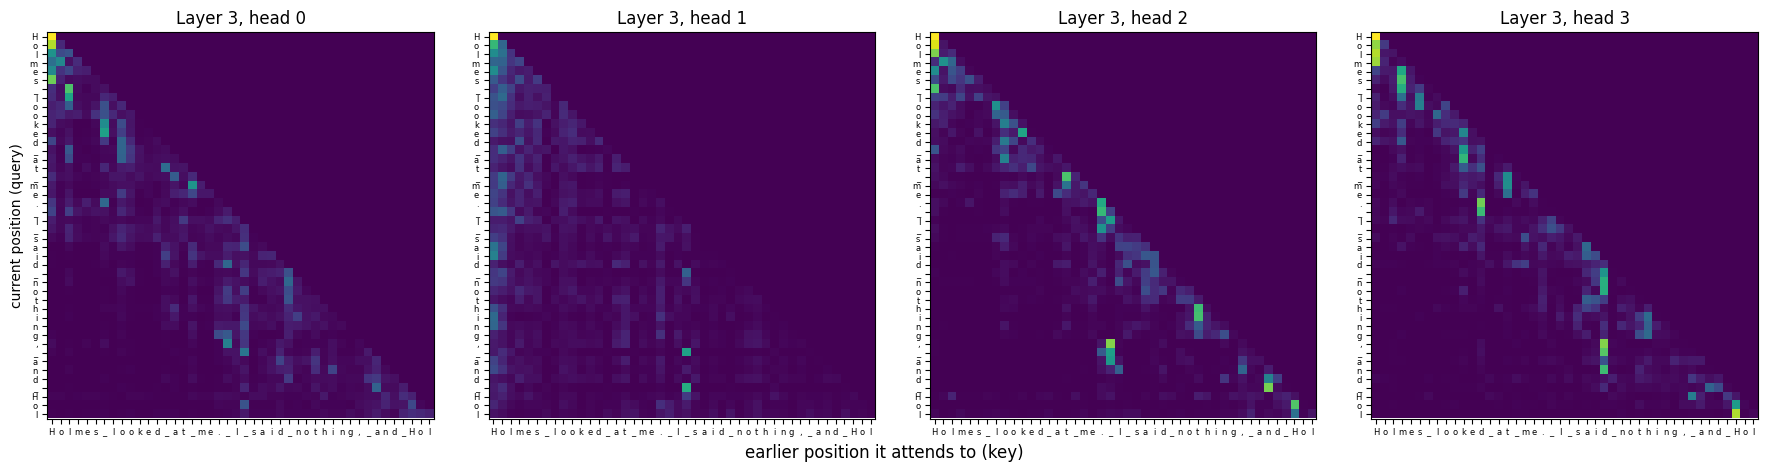

In [ ]:
# Example 2: repeating a name. Does any head look at the earlier "Holmes"?
example_name = "Holmes looked at me. I said nothing, and Hol"
top_attention(transformer, example_name)
plot_attention(transformer, example_name, layer=N_LAYER - 1)

### 7.5 Analysis

- **Which model performed best?** With a fixed budget of 5,000 steps, LSTM achieved the lowest validation loss; however, LSTM is nearing its limits and beginning to overfit, while the Transformer still has room for improvement.
- **Which model trained fastest?** Bigram
- **Which model generated the most realistic text?** LSTM
- **What did the transformer improve compared to the other models?** The dialogue structure is more complete. This passage consists almost entirely of dialogue; each paragraph begins with “ and ends with ,” with a blank line between paragraphs, and concludes with “Why, I told you we’d be serious,” said Holmes. The format—“quotation marks + comma + said + name”—is entirely correct, and the speaker is Holmes, whose name is spelled out in full.
- **Was the improvement worth the added complexity?** Although it takes longer to train and its word accuracy isn't as high as that of LSTM, the Transformer outperforms LSTM in terms of overall semantic understanding and contextual coherence.
- **What did you learn about attention?** Attention allows the model, when predicting each character, to decide on its own which previous positions to look at based on the content, and to directly access any position within the window.